

# **Project** **Task**




#Task 01


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
c_df = pd.read_csv("/content/drive/MyDrive/customer-churn-prediction/customer_churn_prediction.csv")

In [ ]:
print(f'Dataset : {c_df.shape}')

Dataset : (7043, 21)


In [ ]:
# columns & datatypes
c_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# missing value

c_df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
#dublicate
c_df.duplicated().sum()

np.int64(0)

In [ ]:
#desriptive
c_df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
c_df.select_dtypes("object").columns

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')

In [ ]:
print(f"Internetservice Unique Value: {c_df["InternetService"].unique()}")
print(f"Multipleline Unique Value :{c_df["MultipleLines"].unique()}")
print(f"Onlinesecurity unioque value : {c_df["OnlineSecurity"].unique()}")
# c_df["OnlineBackup"].unique()
# c_df["DeviceProtection"].unique()
# c_df["TechSupport"].unique()
c_df["StreamingTV"].unique()
# c_df["StreamingMovies"].unique()
# c_df["Contract"].unique()
# c_df["PaymentMethod"].unique()





Internetservice Unique Value: ['DSL' 'Fiber optic' 'No']
Multipleline Unique Value :['No phone service' 'No' 'Yes']
Onlinesecurity unioque value : ['No' 'Yes' 'No internet service']


array(['No', 'Yes', 'No internet service'], dtype=object)

In [ ]:
#Target-variable distribution

(c_df.Churn.value_counts()  / c_df["Churn"].shape )   *  100


,count
Churn,
No,73.463013
Yes,26.536987


In [ ]:
c_df['Tenure_group'] = pd.cut(
    c_df["tenure"], bins = [-1,12,36,60 , float('inf')], labels=["New", "Medium", "Long-term", "Loyal"])



In [ ]:
# Average Monthly Spend
c_df['TotalCharges'] = pd.to_numeric(c_df['TotalCharges'], errors='coerce')
average_monthly_spend = c_df['TotalCharges'].mean()
print(f"Average Monthly Spend: {average_monthly_spend:.2f}")

Average Monthly Spend: 2283.30


In [ ]:
# family ---> partner + dependents
c_df["family"] =  ((c_df['Partner']  == "Yes") | (c_df['Dependents'] == "Yes")).astype(int)

In [ ]:
c_df["family"].unique()

array([1, 0])

In [ ]:
# service_columns

service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]
c_df['TotalService'] = (c_df[service_columns] == 'Yes').sum(axis=1)

In [ ]:
c_df["Contract"].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

In [ ]:
# Month to month
c_df['IsMonthToMonth'] = (c_df['Contract'] == 'MonthToMonth').astype(int)

In [ ]:
c_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_group,family,TotalService,IsMonthToMonth
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Month-to-month,Yes,Electronic check,29.85,29.85,No,New,1,1,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,One year,No,Mailed check,56.95,1889.50,No,Medium,0,3,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,New,0,3,0
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,One year,No,Bank transfer (automatic),42.30,1840.75,No,Long-term,0,3,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,New,0,1,0


#Task 04

In [ ]:
#What is the overall churn rate?
(c_df['Churn'] == "Yes").mean() * 100


np.float64(26.536987079369588)

In [ ]:
#Which contract type has the highest churn rate?

c_df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).max()


42.70967741935484

#Which subscription type has the highest churn rate?


In [ ]:
c_df.groupby("InternetService")["Churn"].apply(lambda x :(x == "Yes").mean()  * 100 ).max()

41.89276485788114

#Does auto-pay reduce churn?


In [ ]:
c_df.groupby("PaymentMethod")["PaymentMethod"].unique()

,PaymentMethod
PaymentMethod,
Bank transfer (automatic),[Bank transfer (automatic)]
Credit card (automatic),[Credit card (automatic)]
Electronic check,[Electronic check]
Mailed check,[Mailed check]


In [ ]:
c_df["Autopay"] = c_df["PaymentMethod"].isin(["Bank transfer (automatic)" , "Credit card (automatic)" ])

In [ ]:
c_df.groupby("Autopay")["Churn"].apply(lambda x: (x == "Yes").mean()* 100)

,Churn
Autopay,
False,34.674378
True,15.981735


# How much monthly revenue is associated with churned customers?

In [ ]:

churned_revenue = c_df.loc[
    c_df["Churn"] == "Yes", "MonthlyCharges"
].sum()

print("Monthly revenue associated with churn:", churned_revenue)

Monthly revenue associated with churn: 139130.85


#Required Visualizations

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#Churn distribution






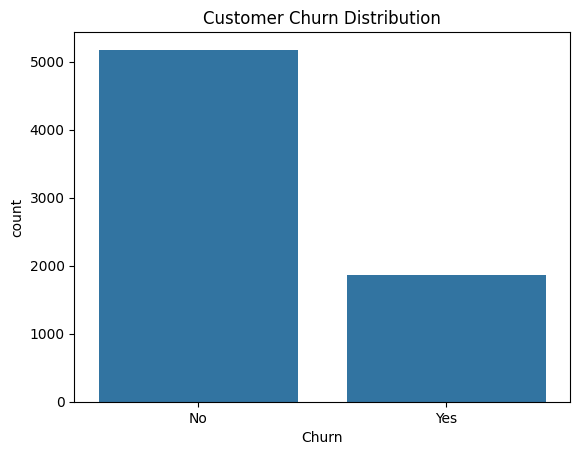

In [ ]:
sns.countplot(data=c_df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

#Churn by contract type

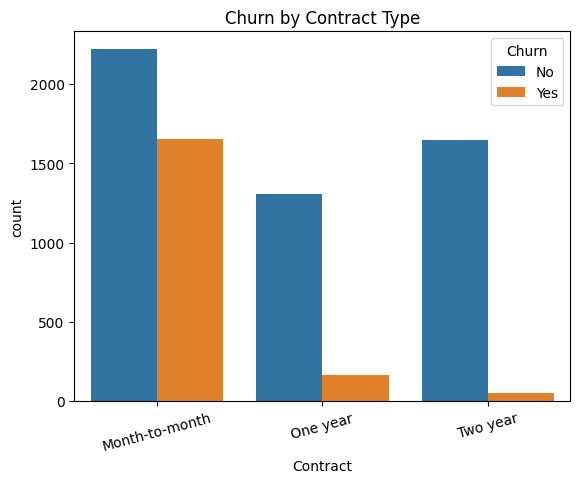

In [ ]:
sns.countplot(data=c_df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

#Task 5: Classification Modeling

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, RocCurveDisplay,
    PrecisionRecallDisplay
)

In [ ]:
c_df.head(2)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_group,family,TotalService,IsMonthToMonth,Autopay
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Yes,Electronic check,29.85,29.85,No,New,1,1,0,False
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,Mailed check,56.95,1889.50,No,Medium,0,3,0,False


In [ ]:
drop_cols = [
    "customerID", "Churn", "TotalCharge",
    "tenure_group", "IsMonthToMonth", "AutoPay"
]

x = c_df.drop(columns=drop_cols, errors="ignore")
y = c_df["Churn"].map({"No": 0, "Yes": 1})

print("Features:", x.shape)
print("Target distribution:")
print(y.value_counts())
print("Missing target values:", y.isna().sum())

Features: (7043, 23)
Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
Missing target values: 0


In [ ]:
numeric_cols = x.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = x.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(numeric_cols)
print(categorical_cols)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'family', 'TotalService', 'Autopay']
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_group']


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
# Numeric columns: missing values fill + scaling
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns: missing values fill + one-hot encoding
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Dono preprocessing steps combine karo
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Training rows:", x_train.shape[0])
print("Testing rows:", x_test.shape[0])
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Training rows: 5634
Testing rows: 1409
Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'family', 'TotalService', 'Autopay']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_group']


In [ ]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges', 'family', 'TotalService',
                                  'Autopay']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod',
                                  'Tenure_group'])])

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

pipelines = {}
results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(x_train, y_train)

    # Default classification threshold = 0.50
    y_pred = pipe.predict(x_test)
    y_prob = pipe.predict_proba(x_test)[:, 1]

    pipelines[name] = pipe
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

print(results_df.round(3))

                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
Logistic Regression     0.739      0.505   0.791     0.617    0.842
KNN                     0.752      0.535   0.511     0.523    0.777
Decision Tree           0.737      0.504   0.503     0.503    0.663
Random Forest           0.780      0.613   0.465     0.529    0.821


                     Accuracy  Precision    Recall  F1-Score   ROC-AUC
Model                                                                 
Logistic Regression  0.738822   0.505119  0.791444  0.616667  0.841652
Random Forest        0.779986   0.612676  0.465241  0.528875  0.821075
KNN                  0.752307   0.535014  0.510695  0.522572  0.777359
Decision Tree        0.736693   0.504021  0.502674  0.503347  0.662693


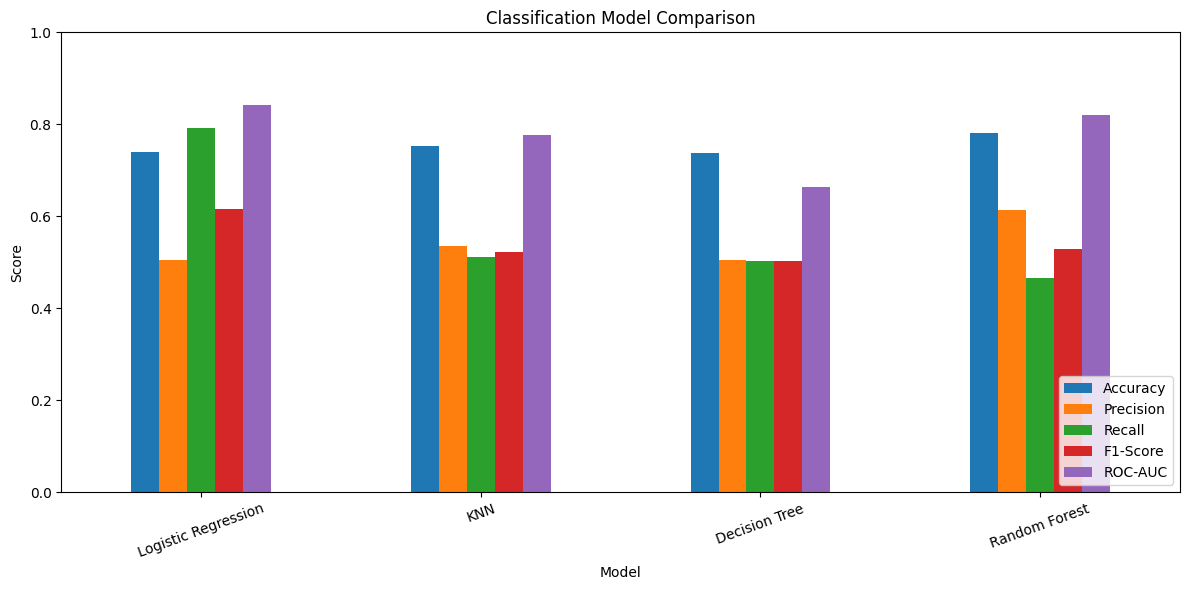

In [ ]:
print(results_df.sort_values("F1-Score", ascending=False))

results_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



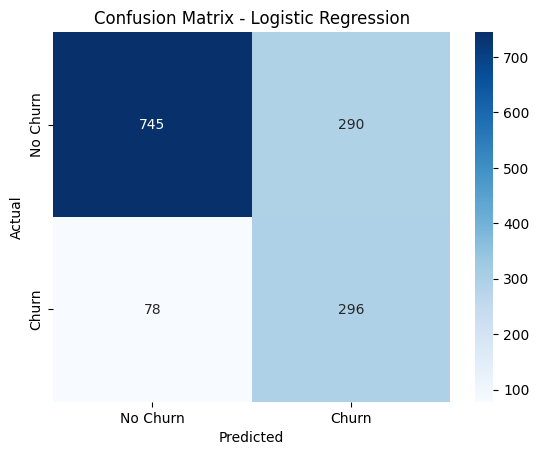


KNN
              precision    recall  f1-score   support

    No Churn       0.83      0.84      0.83      1035
       Churn       0.54      0.51      0.52       374

    accuracy                           0.75      1409
   macro avg       0.68      0.68      0.68      1409
weighted avg       0.75      0.75      0.75      1409



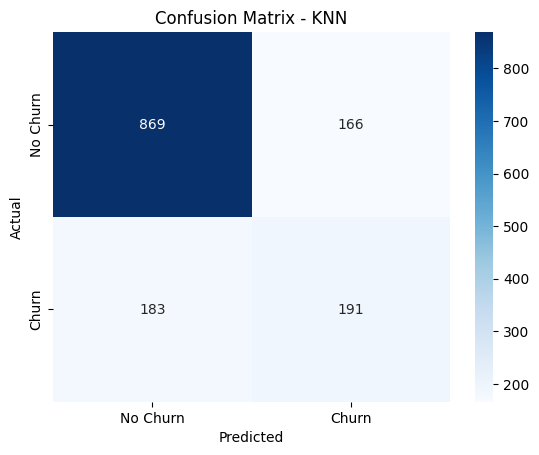


Decision Tree
              precision    recall  f1-score   support

    No Churn       0.82      0.82      0.82      1035
       Churn       0.50      0.50      0.50       374

    accuracy                           0.74      1409
   macro avg       0.66      0.66      0.66      1409
weighted avg       0.74      0.74      0.74      1409



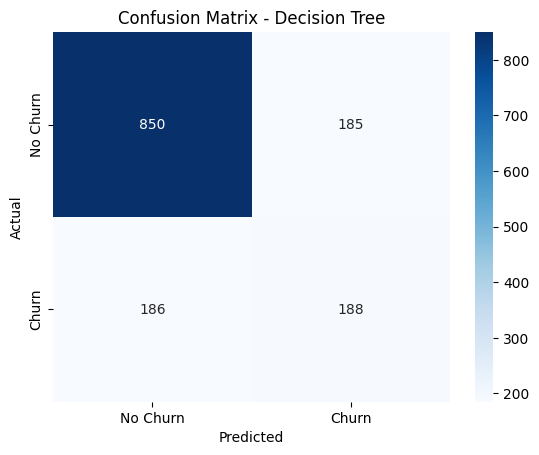


Random Forest
              precision    recall  f1-score   support

    No Churn       0.82      0.89      0.86      1035
       Churn       0.61      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



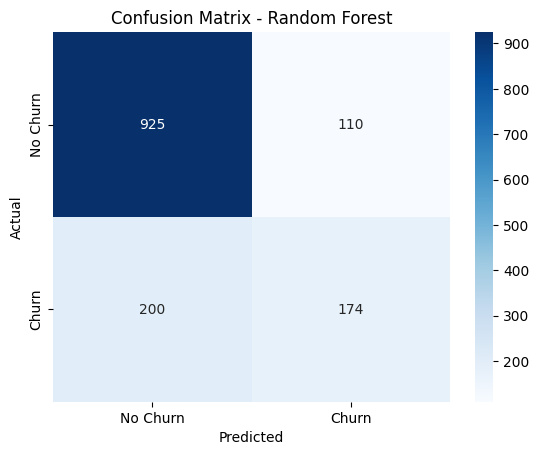

In [ ]:
for name in models:

    print("\n", "=" * 50)
    print(name)
    print(classification_report(
        y_test,
        predictions[name],
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test, predictions[name], labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

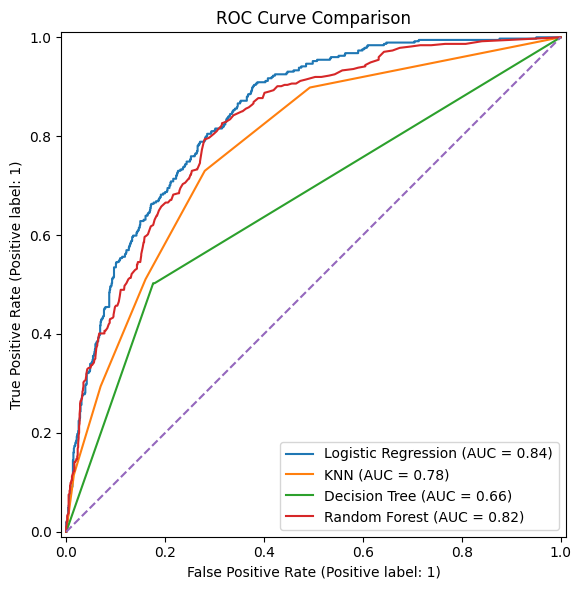

In [ ]:
plt.figure(figsize=(9, 6))

for name in models:
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[name],
        name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

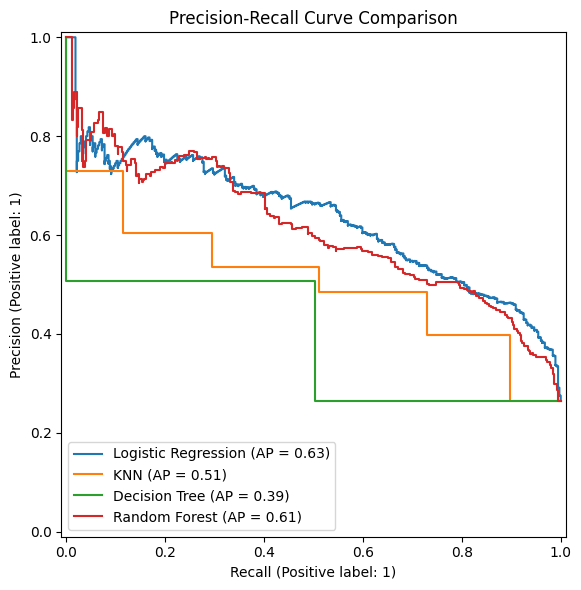

In [ ]:
plt.figure(figsize=(9, 6))

for name in models:
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities[name],
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curve Comparison")
plt.tight_layout()
plt.show()

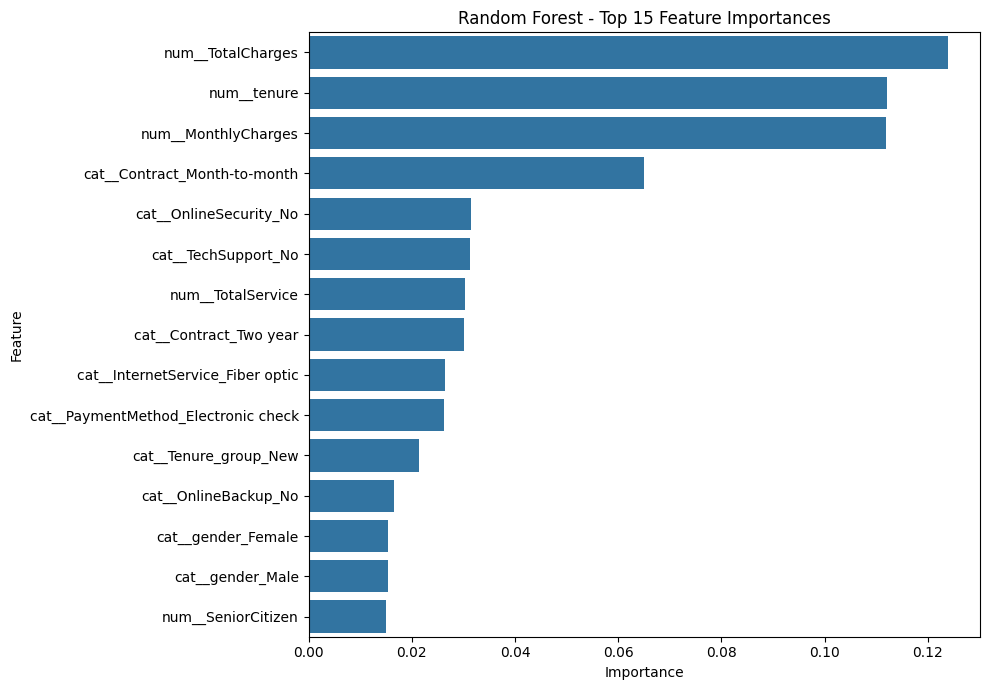

In [ ]:
rf_pipe = pipelines["Random Forest"]

feature_names = (
    rf_pipe.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = rf_pipe.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(15)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df["F1-Score"].idxmax()
best_model = pipelines[best_model_name]

print("Best model by F1-score:", best_model_name)

import joblib

joblib.dump(best_model, "best_churn_model.pkl")
joblib.dump(list(x.columns), "model_features.pkl")

Best model by F1-score: Logistic Regression


['model_features.pkl']

#Task 6: Threshold Analysis

In [ ]:
import ipywidgets as widgets
from IPython.display import display

# Random Forest ke predicted churn probabilities
y_prob = probabilities["Random Forest"]

def threshold_analysis(threshold=0.50):

    # Threshold ke mutabiq predictions
    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test, y_pred_threshold, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred_threshold, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred_threshold, zero_division=0
    )

    print(f"Threshold: {threshold:.2f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1-score: {f1:.3f}")
    print(f"False positives: {fp}")
    print(f"False negatives: {fn}")
    print(f"High-risk customers: {y_pred_threshold.sum()}")

slider = widgets.FloatSlider(
    value=0.50,
    min=0.10,
    max=0.90,
    step=0.05,
    description="Threshold:",
    continuous_update=False
)

widgets.interact(
    threshold_analysis,
    threshold=slider
)

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Threshold:', max=0.9, min=0…

<function __main__.threshold_analysis(threshold=0.5)>

In [ ]:
import joblib

joblib.dump(x_test, "/content/x_test.pkl")
joblib.dump(y_test, "/content/y_test.pkl")

print("Test data saved successfully!")
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

Test data saved successfully!
x_test shape: (1409, 23)
y_test shape: (1409,)


In [ ]:
# Save Task 5 model comparison results
comparison_df = results_df.copy()

comparison_df.index.name = "Model"
comparison_df = comparison_df.reset_index()

comparison_df.columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_df.to_csv(
    "/content/model_comparison.csv",
    index=False
)

display(comparison_df)

print("Model comparison CSV saved successfully!")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.738822,0.505119,0.791444,0.616667,0.841652
1,KNN,0.752307,0.535014,0.510695,0.522572,0.777359
2,Decision Tree,0.736693,0.504021,0.502674,0.503347,0.662693
3,Random Forest,0.779986,0.612676,0.465241,0.528875,0.821075


Model comparison CSV saved successfully!


#Task 7: Streamlit Application


In [ ]:
!pip install -q streamlit pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
!pkill -f "streamlit run /content/app.py" || true


^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  --browser.gatherUsageStats false \
  > /content/streamlit.log 2>&1 &

In [194]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501, height=800)

<IPython.core.display.Javascript object>

In [195]:
import os
import shutil

# Existing Google Drive project folder
project_dir = "/content/drive/MyDrive/customer-churn-prediction"
os.makedirs(project_dir, exist_ok=True)

# Files to copy from Colab
files_to_copy = [
    "app.py",
    "best_churn_model.pkl",
    "model_features.pkl",
    "model_comparison.csv",
    "x_test.pkl",
    "y_test.pkl"
]

for filename in files_to_copy:
    source = f"/content/{filename}"
    destination = os.path.join(project_dir, filename)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print(f"Copied: {filename}")
    else:
        print(f"Not found: {filename}")

print("\nProject folder:", project_dir)
print("Files:", os.listdir(project_dir))

Copied: app.py
Copied: best_churn_model.pkl
Copied: model_features.pkl
Copied: model_comparison.csv
Copied: x_test.pkl
Copied: y_test.pkl

Project folder: /content/drive/MyDrive/customer-churn-prediction
Files: ['customer_churn_prediction.csv', 'app.py', 'best_churn_model.pkl', 'model_features.pkl', 'model_comparison.csv', 'x_test.pkl', 'y_test.pkl']
